# Notebook 3: Calibrated Cold Stop

**Course project: Foundations of LLMs (AI60213)** · Base paper: *Soft Thinking* (Zhang et al., NeurIPS 2025)

Notebook 1 found a second, independent limitation of Soft Thinking at small scale: **its stopping rule, Cold Stop, never fires.** Its thresholds were set for 32B+ models, and with them 28% of questions run to the 2,048-token thinking budget. This notebook **calibrates Cold Stop for the small model from training traces alone**, without touching the test set, and then measures the effect on the 250 GSM8K test questions.

**Contents**

0. Briefing
1. Setup, including Notebook 1's and Notebook 2's results
2. Shared machinery (identical to Notebooks 1–2)
3. Overthinking: how much thinking happens after the answer is already found?
4. Calibration on training traces
5. Evaluation on the test questions
6. Comparison with the paper's Cold Stop
7. Conclusion

---
# Part 0: Briefing

## 0.1 Cold Stop

Soft Thinking ends the thinking phase early once the concept token's entropy stays below $\tau$ for $k$ **consecutive** steps. The paper uses settings tuned for large models; Notebooks 1–2 used $\tau = 0.01$, $k = 128$, and Cold Stop fired on **0%** of questions.

## 0.2 Calibration without the test set

Decoding is deterministic, so for any $(\tau, k)$ we can compute **exactly** where Cold Stop *would* have fired on an existing Soft Thinking trace: up to that step the trace is identical. The only unknown is whether the answer survives the cut. As a proxy we check whether the correct answer **has already appeared in the thinking** before the cut.

On the 400 **training** traces collected in Notebook 2, for every $(\tau, k)$ on a fixed grid:

* **Token savings:** the fraction of all thinking tokens that the cut removes.
* **Harm rate:** among originally *correct* traces, the fraction cut **before** the answer appears in the thinking. This is conservative: a correct trace whose thinking never contains the answer counts as harmed whenever it is cut. Traces whose answer number also appears in the question are ambiguous and are excluded from the harm rate.

**Selection rule, fixed in advance:** choose the $(\tau, k)$ with the **largest token savings whose harm rate is at most 2%**. If no setting qualifies, the paper's setting is kept.

## 0.3 Protocol and runtime (one T4)

1. **Overthinking analysis** of the training traces (CPU, about 1 min).
2. **Calibration** on the training traces (CPU, about 1 min). An offline prediction for the test traces is printed for reference but **not** used for selection.
3. **One test run** with the calibrated Cold Stop: about 60–80 min for 250 questions (less if thinking gets shorter). This is followed by the gap diagnosis (about 4 min) so that Notebook 4 can compare against it.
4. **Paired comparison** with Notebook 1 on the same questions: accuracy (McNemar) and thinking tokens (Wilcoxon).

| | QUICK | FULL |
|---|---|---|
| Total | ~15 min | ~1.5 h |

**Inputs on Kaggle:** *Add Input → Notebooks (Your Work)* → Notebook 1 **and** Notebook 2, both finished FULL runs.

**Outputs used by Notebook 4:** `cold_stop_calibration.json`, `ccs_test.pkl`, `diag_ccs.pkl`.

---
# Part 1: Setup

In [1]:
#!pip install -q -U "transformers>=4.51" accelerate datasets

In [2]:
# Optional: a Hugging Face token avoids download rate limits (Kaggle: Add-ons -> Secrets -> HF_TOKEN).
# from kaggle_secrets import UserSecretsClient; import os
# os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [3]:
import os, re, glob, json, math, time, random, pickle
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from dataclasses import replace

RUN_MODE = "FULL"      # "QUICK": short smoke test | "FULL": the reported numbers
SEED = 0

@dataclass
class Config:
    n_test: int = 250               # first n GSM8K test questions
    batch_size: int = 16            # questions decoded in parallel
    # Soft Thinking settings (identical in both notebooks)
    max_think_tokens: int = 2048
    max_answer_tokens: int = 512
    temperature: float = 0.6
    top_k: int = 15
    top_p: float = 0.95
    min_p: float = 0.001
    cold_stop: bool = True
    cold_stop_tau: float = 0.01
    cold_stop_len: int = 128
    # Diagnosis
    max_probe_steps: int = 64       # mixed steps probed per trace (memory cap)
    # Cold Stop calibration (on training traces only)
    cal_taus: tuple = (0.01, 0.05, 0.1, 0.25, 0.5)
    cal_lens: tuple = (16, 32, 48, 64, 96, 128, 192, 256)
    harm_target: float = 0.02       # max fraction of correct training traces cut before the answer appears

CFG = Config() if RUN_MODE == "FULL" else Config(n_test=16)

OUT_DIR = ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".") + f"/calibrated_cold_stop_{RUN_MODE.lower()}"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    # A T4 (compute capability 7.5) has no native bfloat16, so float16 is used there.
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DTYPE = torch.float32
    print("No GPU found: FULL mode is not practical on CPU.")
print(f"RUN_MODE={RUN_MODE} | dtype={DTYPE} | outputs -> {OUT_DIR}")
print("torch", torch.__version__, "| transformers", transformers.__version__)
CFG

GPU: Tesla T4
RUN_MODE=FULL | dtype=torch.float16 | outputs -> /kaggle/working/calibrated_cold_stop_full
torch 2.11.0+cu130 | transformers 5.20.2


Config(n_test=250, batch_size=16, max_think_tokens=2048, max_answer_tokens=512, temperature=0.6, top_k=15, top_p=0.95, min_p=0.001, cold_stop=True, cold_stop_tau=0.01, cold_stop_len=128, max_probe_steps=64, cal_taus=(0.01, 0.05, 0.1, 0.25, 0.5), cal_lens=(16, 32, 48, 64, 96, 128, 192, 256), harm_target=0.02)

## 1.1 Inputs: Notebook 1 (paper on test) and Notebook 2 (training traces)

In [4]:
def find_output(folder):
    """Locate another notebook's output folder (attached on Kaggle via Add Input, or in the working dir)."""
    for mode in ("full", "quick"):
        for root in ("/kaggle/input", "."):
            hits = sorted(glob.glob(f"{root}/**/{folder}_{mode}/config.json", recursive=True))
            if hits:
                return os.path.dirname(hits[0])
    return None

NB1_DIR, NB2_DIR = find_output("soft_thinking_paper"), find_output("concept_adapter")
assert NB1_DIR, "Notebook 1's output not found: Add Input -> Notebooks (Your Work) -> Notebook 1 (finished run)."
assert NB2_DIR, "Notebook 2's output not found: Add Input -> Notebooks (Your Work) -> Notebook 2 (finished run)."

def read_pkl(folder, name):
    with open(f"{folder}/{name}.pkl", "rb") as f:
        return pickle.load(f)

paper_test = read_pkl(NB1_DIR, "soft_test")[:CFG.n_test]
train_traces = read_pkl(NB2_DIR, "train_traces")
paper_time = json.load(open(f"{NB1_DIR}/soft_test_time.json"))
test_set = [{"id": r["id"], "q": r["q"], "a": r["gold"]} for r in paper_test]
print("Notebook 1:", NB1_DIR, "| Notebook 2:", NB2_DIR)
print(f"paper test results: {len(paper_test)} | training traces (calibration): {len(train_traces)}")

Notebook 1: /kaggle/input/notebooks/anarvaaa/fllm-project-nb1/soft_thinking_paper_full | Notebook 2: /kaggle/input/notebooks/anarvaaa/fllm-project-nb2/concept_adapter_full
paper test results: 250 | training traces (calibration): 400


## 1.2 Model

In [5]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"                                  # batched decoding
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
_dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **{_dtype_kw: DTYPE}).to(DEVICE).eval()
model.requires_grad_(False)                                # the LLM is always frozen

E = model.get_input_embeddings().weight                    # (vocab, d): input embedding matrix
D_MODEL = E.shape[1]
N_LAYERS = model.config.num_hidden_layers
END_THINK_ID = tok.convert_tokens_to_ids("</think>")
assert tok.decode([END_THINK_ID]) == "</think>", "model has no </think> token: use a reasoning model"
EOS_IDS = {i for i in {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")} if i is not None}
EOS_ID = min(EOS_IDS)
FORCE_IDS = tok("</think>\n\n", add_special_tokens=False).input_ids   # appended when thinking ends
print(f"E: {tuple(E.shape)} | layers: {N_LAYERS} | </think> = {END_THINK_ID} | eos = {EOS_IDS} | "
      f"frozen params: {sum(p.numel() for p in model.parameters())/1e9:.2f}B")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

E: (151936, 2048) | layers: 28 | </think> = 151668 | eos = {151645} | frozen params: 1.72B


---
# Part 2: Shared machinery

The code in this part is identical to Notebooks 1–2: concept tokens, the batched Soft Thinking loop, the runner and the gap diagnosis. The only difference in this notebook is the Cold Stop setting passed to it.

In [6]:
def concept_tokens(logits: torch.Tensor, cfg: Config = CFG):
    """logits (B, V) -> concept-token weights (B, K) summing to 1 (zeros = filtered out) and their ids (B, K).
    Column 0 is always the argmax."""
    probs = torch.softmax(logits / cfg.temperature, dim=-1)
    p, ids = probs.topk(cfg.top_k, dim=-1)
    keep = (p.cumsum(-1) - p) < cfg.top_p                        # top-p on the true probabilities
    keep &= p >= cfg.min_p * p[:, :1]                            # min-p relative to the argmax
    keep[:, 0] = True
    p = p * keep
    return p / p.sum(-1, keepdim=True), ids


def entropies(p: torch.Tensor) -> torch.Tensor:
    """H(c_t) for Cold Stop."""
    return -(p * p.clamp_min(1e-12).log()).sum(-1)


def soft_embeddings(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """e~_t = sum_k c_t[k] e(k), computed in fp32."""
    return torch.einsum("bk,bkd->bd", p.float(), E[ids].float())


def candidate_norm(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """sum_k c_t[k] ||e(k)||: the norm a real token would have at this step."""
    return (p.float() * E[ids].float().norm(dim=-1)).sum(-1)


def build_prompt(question: str) -> str:
    msgs = [{"role": "user",
             "content": question + "\nPlease reason step by step, and put your final answer within \\boxed{}."}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=True)
    if not text.rstrip().endswith("<think>"):
        text += "<think>\n"
    return text


def extract_boxed(text: str):
    """Content of the last \\boxed{...}; falls back to the last number in the text."""
    start = text.rfind("\\boxed{")
    if start == -1:
        nums = re.findall(r"-?\d[\d,]*\.?\d*", text)
        return nums[-1] if nums else None
    i, depth, buf = start + len("\\boxed{"), 1, []
    while i < len(text):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            break
        buf.append(text[i]); i += 1
    return "".join(buf)


def to_number(s):
    if s is None:
        return None
    nums = re.findall(r"-?\d+\.?\d*", s.replace(",", ""))
    return float(nums[0]) if nums else None

In [7]:
THINK, FORCE, ANSWER, DONE = range(4)

@torch.no_grad()
def soft_think_batch(questions, cfg: Config = CFG, adapter=None):
    """Batched Soft Thinking. If `adapter` is given, it is applied as adapter(e~, weights, ids) to every
    genuinely mixed concept token (>= 2 surviving candidates) before it is fed to the model."""
    enc = tok([build_prompt(q) for q in questions], return_tensors="pt", padding=True).to(DEVICE)
    mask = enc.attention_mask
    pos = (mask.cumsum(-1) - 1).clamp_min(0)                    # left padding: explicit positions
    out = model(input_ids=enc.input_ids, attention_mask=mask, position_ids=pos, use_cache=True, logits_to_keep=1)
    past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), pos[:, -1] + 1

    B = len(questions)
    phase, queue, low_run = [THINK] * B, [[] for _ in range(B)], [0] * B
    recs = [{"steps": [], "answer_ids": [], "stop_reason": None} for _ in range(B)]
    while True:
        p, cids = concept_tokens(logits, cfg)
        H = entropies(p)
        p_c, ids_c, H_c = p.cpu(), cids.cpu(), H.cpu()
        token_ids, soft_rows = [EOS_ID] * B, []
        for b in range(B):
            if phase[b] == THINK:
                keep = p_c[b] > 0
                step = {"ids": ids_c[b][keep].tolist(), "probs": p_c[b][keep].tolist(), "entropy": float(H_c[b])}
                recs[b]["steps"].append(step)
                low_run[b] = low_run[b] + 1 if step["entropy"] < cfg.cold_stop_tau else 0
                if step["ids"][0] == END_THINK_ID or step["ids"][0] in EOS_IDS:
                    reason = "</think>"
                elif cfg.cold_stop and low_run[b] >= cfg.cold_stop_len:
                    reason = "cold stop"
                elif len(recs[b]["steps"]) >= cfg.max_think_tokens:
                    reason = "budget"
                else:
                    soft_rows.append(b)
                    continue
                recs[b]["stop_reason"] = reason                # the stopping step itself is never fed
                phase[b], queue[b] = FORCE, list(FORCE_IDS)
            if phase[b] == FORCE:
                token_ids[b] = queue[b].pop(0)
                if not queue[b]:
                    phase[b] = ANSWER
            elif phase[b] == ANSWER:
                nxt = int(ids_c[b][0])                         # greedy answer token
                if nxt in EOS_IDS or len(recs[b]["answer_ids"]) >= cfg.max_answer_tokens:
                    phase[b] = DONE
                else:
                    recs[b]["answer_ids"].append(nxt)
                    token_ids[b] = nxt
        if all(ph == DONE for ph in phase):
            break
        emb = E[torch.tensor(token_ids, device=DEVICE)].clone()
        if soft_rows:
            r = torch.tensor(soft_rows, device=DEVICE)
            se = soft_embeddings(p[r], cids[r])
            if adapter is not None:
                mixed = (p[r] > 0).sum(-1) > 1
                se = torch.where(mixed[:, None], adapter(se, p[r], cids[r]), se)
            emb[r] = se.to(E.dtype)
        mask = torch.cat([mask, mask.new_ones(B, 1)], dim=1)
        out = model(inputs_embeds=emb[:, None], attention_mask=mask, position_ids=next_pos[:, None],
                    past_key_values=past, use_cache=True, logits_to_keep=1)
        past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), next_pos + 1
    return recs

In [8]:
def save_pkl(obj, name):
    with open(f"{OUT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)


def load_pkl(name, folder=None):
    path = f"{folder or OUT_DIR}/{name}.pkl"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def run_soft_thinking(data, name, cfg: Config = CFG, adapter=None):
    """Decode `data` in batches, parse answers, save results (with every concept token) and the wall time."""
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded {len(cached)} cached results")
        return cached
    results, t_start = [], time.time()
    for i in range(0, len(data), cfg.batch_size):
        batch = data[i:i + cfg.batch_size]
        t0 = time.time()
        recs = soft_think_batch([ex["q"] for ex in batch], cfg, adapter)
        for ex, r in zip(batch, recs):
            answer = tok.decode(r["answer_ids"], skip_special_tokens=True).strip()
            pred = to_number(extract_boxed(answer))
            results.append({"id": ex["id"], "q": ex["q"], "gold": ex["a"], "pred": pred,
                            "correct": pred is not None and abs(pred - ex["a"]) < 1e-4,
                            "think_tokens": len(r["steps"]), "stop_reason": r["stop_reason"],
                            "answer": answer, "steps": r["steps"]})
        acc = np.mean([x["correct"] for x in results])
        print(f"[{name}] {len(results):4d}/{len(data)} | batch {time.time()-t0:6.1f}s | "
              f"elapsed {(time.time()-t_start)/60:5.1f} min | running acc {acc:.3f}")
    save_pkl(results, name)
    with open(f"{OUT_DIR}/{name}_time.json", "w") as f:
        json.dump({"seconds": time.time() - t_start, "questions": len(data)}, f)
    return results


def tail_repetition(r, n=4, tail=256):
    """Fraction of repeated 4-grams in the last 256 argmax thinking tokens (0 = no repetition, ~1 = a loop)."""
    ids = [s["ids"][0] for s in r["steps"]][-tail:]
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def summarize(results, label):
    fed = [s for r in results for s in r["steps"][:-1]]
    return {
        "system": label,
        "accuracy": np.mean([r["correct"] for r in results]),
        "avg think tokens": np.mean([r["think_tokens"] for r in results]),
        "stop: </think>": np.mean([r["stop_reason"] == "</think>" for r in results]),
        "stop: cold stop": np.mean([r["stop_reason"] == "cold stop" for r in results]),
        "stop: budget": np.mean([r["stop_reason"] == "budget" for r in results]),
        "no \\boxed answer": np.mean(["\\boxed{" not in r["answer"] for r in results]),
        "mixed steps": np.mean([len(s["ids"]) > 1 for s in fed]) if fed else float("nan"),
        "tail repetition": np.mean([tail_repetition(r) for r in results]),
    }

In [9]:
def trace_tensors(steps):
    """Dense (T, K) weights / ids of the concept tokens that were FED (all but the stopping step)."""
    fed = steps[:-1]
    T, K = len(fed), max((len(s["ids"]) for s in fed), default=1)
    P = torch.zeros(T, K, device=DEVICE)
    C = torch.zeros(T, K, dtype=torch.long, device=DEVICE)
    for t, s in enumerate(fed):
        P[t, :len(s["ids"])] = torch.tensor(s["probs"], device=DEVICE)
        C[t, :len(s["ids"])] = torch.tensor(s["ids"], device=DEVICE)
    return P, C


def trace_inputs(question, steps, adapter=None):
    """Exactly what the model was fed: prompt embeddings + one (soft, possibly adapted) embedding per step."""
    prompt_ids = tok(build_prompt(question), return_tensors="pt").input_ids[0].to(DEVICE)
    P, C = trace_tensors(steps)
    se = soft_embeddings(P, C)
    support = (P > 0).sum(-1)
    fed = se if adapter is None else torch.where((support > 1)[:, None], adapter(se, P, C), se)
    return torch.cat([E[prompt_ids], fed.to(E.dtype)]), len(prompt_ids), P, C, support, se


def pick_mixed_steps(support, cap, seed=SEED):
    idx = (support > 1).nonzero().squeeze(-1)
    if len(idx) > cap:
        g = torch.Generator().manual_seed(seed)
        idx = idx[torch.randperm(len(idx), generator=g)[:cap].to(idx.device)].sort().values
    return idx


def probe_mask(L, positions):
    """(1,1,Q,L+Q) mask: probe j sees cached keys < positions[j] and itself, nothing else."""
    Q = len(positions)
    m = torch.zeros(Q, L + Q, dtype=torch.bool, device=DEVICE)
    m[:, :L] = torch.arange(L, device=DEVICE)[None, :] < positions[:, None]
    m[torch.arange(Q, device=DEVICE), L + torch.arange(Q, device=DEVICE)] = True
    return m[None, None]


def flatten_candidates(P, C, t_idx, P0):
    """One row per (mixed step, candidate): token id, weight, owning step, absolute position."""
    sel = P[t_idx] > 0
    owner = torch.arange(len(t_idx), device=DEVICE)[:, None].expand_as(sel)[sel]
    return C[t_idx][sel], P[t_idx][sel], owner, (P0 + t_idx)[owner]


def superpose(hidden_states, w, owner, M):
    """Per layer l: sum_k c_k h_l(e(k)) for every mixed step -> list of (M, d) fp32 tensors."""
    return [torch.zeros(M, D_MODEL, device=DEVICE).index_add_(0, owner, w[:, None] * h[0].float())
            for h in hidden_states]


@torch.no_grad()
def mixture_target(h_cand, w, owner, M, chunk=256):
    """q_t = sum_k c_k softmax(lm_head(h(e(k)))): the intended next-token distribution, (M, V) fp32."""
    q = torch.zeros(M, model.lm_head.out_features, device=DEVICE)
    for i in range(0, len(owner), chunk):
        probs = torch.softmax(model.lm_head(h_cand[i:i + chunk].to(DTYPE)).float(), dim=-1)
        q.index_add_(0, owner[i:i + chunk], w[i:i + chunk, None] * probs)
    return q


def kl_to_target(q, logits):
    logp = F.log_softmax(logits.float(), dim=-1)
    return (q * (q.clamp_min(1e-12).log() - logp)).sum(-1)


@torch.no_grad()
def diagnose_trace(res, adapter=None, cap=CFG.max_probe_steps):
    """All gap metrics for up to `cap` mixed steps of one finished trace (two forward passes)."""
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter)
    t_idx = pick_mixed_steps(support, cap)
    if len(t_idx) == 0:
        return None
    out = model.model(inputs_embeds=X[None], use_cache=True, output_hidden_states=True)      # pass 1: real trace
    L = X.shape[0]
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, pos), position_ids=pos[None],
                        past_key_values=out.past_key_values, output_hidden_states=True)       # pass 2: probes
    M, rows = len(t_idx), P0 + t_idx
    targets = superpose(probe.hidden_states, w, owner, M)
    h_soft = [h[0, rows].float() for h in out.hidden_states]
    rel = torch.stack([(hs - tg).norm(dim=-1) / tg.norm(dim=-1) for hs, tg in zip(h_soft, targets)])   # (L+1, M)
    h_last = probe.hidden_states[-1][0].float()
    first = torch.cat([torch.zeros(1, dtype=torch.long, device=DEVICE), (owner[1:] != owner[:-1]).nonzero().squeeze(-1) + 1])
    q = mixture_target(h_last, w, owner, M)
    logits_soft = model.lm_head(h_soft[-1].to(DTYPE))
    x_in = X[rows].float()
    df = pd.DataFrame({
        "id": res["id"], "correct": res["correct"], "step": t_idx.cpu().numpy(),
        "entropy": [res["steps"][int(t)]["entropy"] for t in t_idx],
        "support": support[t_idx].cpu().numpy(),
        "norm_ratio": (x_in.norm(dim=-1) / candidate_norm(P[t_idx], C[t_idx])).cpu().numpy(),
        "input_shift": ((x_in - se[t_idx]).norm(dim=-1) / se[t_idx].norm(dim=-1)).cpu().numpy(),
        "gap_layers": rel[1:].mean(0).cpu().numpy(),
        "gap_hidden": rel[-1].cpu().numpy(),
        "dist_top1": ((h_soft[-1] - h_last[first]).norm(dim=-1) / h_last[first].norm(dim=-1)).cpu().numpy(),
        "kl_output": kl_to_target(q, logits_soft).cpu().numpy(),
        "argmax_agree": (logits_soft.argmax(-1) == q.argmax(-1)).cpu().numpy(),
    })
    for l in range(rel.shape[0]):
        df[f"gap_L{l}"] = rel[l].cpu().numpy()
    return df


def diagnose_run(results, name, adapter=None):
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded cached diagnosis")
        return cached
    t0 = time.time()
    diag = pd.concat([d for d in (diagnose_trace(r, adapter) for r in results) if d is not None], ignore_index=True)
    print(f"[{name}] {len(diag)} mixed steps from {diag['id'].nunique()} traces in {time.time()-t0:.0f}s")
    save_pkl(diag, name)
    return diag


def diag_summary(diag, label):
    return {
        "system": label,
        "mixed steps probed": len(diag),
        "norm ratio (mean)": diag["norm_ratio"].mean(),
        "input shift (mean)": diag["input_shift"].mean(),
        "gap, all layers (mean)": diag["gap_layers"].mean(),
        "gap, final layer (mean)": diag["gap_hidden"].mean(),
        "dist to top-1, final layer (mean)": diag["dist_top1"].mean(),
        "closer to top-1 than to superposition": (diag["dist_top1"] < diag["gap_hidden"]).mean(),
        "output KL (mean)": diag["kl_output"].mean(),
        "output KL (median)": diag["kl_output"].median(),
        "argmax agrees with mixture": diag["argmax_agree"].mean(),
    }

In [10]:
from math import comb
from scipy.stats import wilcoxon

def paired_accuracy(a_res, b_res, a_name, b_name):
    """2x2 table (rows: a, columns: b) + exact McNemar test on the same questions."""
    a = {r["id"]: r for r in a_res}; b = {r["id"]: r for r in b_res}
    ids = sorted(set(a) & set(b))
    both = sum(a[i]["correct"] and b[i]["correct"] for i in ids)
    only_a = sum(a[i]["correct"] and not b[i]["correct"] for i in ids)
    only_b = sum(b[i]["correct"] and not a[i]["correct"] for i in ids)
    neither = len(ids) - both - only_a - only_b
    n = only_a + only_b
    p = min(1.0, 2 * sum(comb(n, k) for k in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    table = pd.DataFrame([[both, only_a], [only_b, neither]],
                         index=[f"{a_name} correct", f"{a_name} wrong"], columns=[f"{b_name} correct", f"{b_name} wrong"])
    return table, {"comparison": f"{b_name} vs {a_name}", "questions": len(ids),
                   f"{a_name}-only correct": only_a, f"{b_name}-only correct": only_b, "McNemar p": p}


def paired_wilcoxon(x, y):
    """Two-sided Wilcoxon signed-rank p for paired samples (1.0 if all differences are zero)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    if np.allclose(x, y):
        return 1.0
    return float(wilcoxon(y, x).pvalue)


def paired_tokens(a_res, b_res):
    a = {r["id"]: r["think_tokens"] for r in a_res}; b = {r["id"]: r["think_tokens"] for r in b_res}
    ids = sorted(set(a) & set(b))
    x, y = np.array([a[i] for i in ids]), np.array([b[i] for i in ids])
    return {"mean tokens a": x.mean(), "mean tokens b": y.mean(), "relative change": (y.sum() - x.sum()) / x.sum(),
            "b shorter on": f"{(y < x).mean():.0%}", "Wilcoxon p": paired_wilcoxon(x, y)}

---
# Part 3: Overthinking in the training traces

For each training trace we find the **first thinking step at which the correct answer has been written** in the readable (argmax) trace. Everything after it is verification, re-derivation or looping. If much of the thinking happens after the answer is already there, an earlier stop can save tokens without losing answers.

In [11]:
_piece_cache = {}
def piece(i):
    if i not in _piece_cache:
        _piece_cache[i] = tok.decode([i])
    return _piece_cache[i]


def gold_patterns(g):
    s = str(int(g)) if float(g).is_integer() else str(g)
    forms = {s} | ({f"{int(g):,}"} if float(g).is_integer() and abs(g) >= 1000 else set())
    return [re.compile(r"(?<![\d.,])" + re.escape(f) + r"(?![\d]|[.,]\d)") for f in forms]


def answer_step(r):
    """Index of the thinking step that completes the first occurrence of the gold answer in the argmax trace.
    None = ambiguous (the answer number also appears in the question); -1 = never appears in the thinking."""
    pats = gold_patterns(r["gold"])
    if any(p.search(r["q"]) for p in pats):
        return None
    pieces = [piece(s["ids"][0]) for s in r["steps"]]
    ends = np.cumsum([len(x) for x in pieces])
    text = "".join(pieces)
    hits = [m for m in (p.search(text) for p in pats) if m]
    if not hits:
        return -1
    return int(np.searchsorted(ends, min(m.end() for m in hits)))


for r in train_traces:
    r["_ans_step"] = answer_step(r)

ov = pd.DataFrame([{"id": r["id"], "correct": r["correct"], "stop": r["stop_reason"], "tokens": r["think_tokens"],
                    "ans_step": r["_ans_step"]} for r in train_traces])
known = ov[ov["correct"] & ov["ans_step"].notna() & (ov["ans_step"] >= 0)].copy()
known["after_answer"] = 1 - (known["ans_step"] + 1) / known["tokens"]
print(f"training traces: {len(ov)} | correct: {ov['correct'].sum()} | ambiguous (answer in question): {ov['ans_step'].isna().sum()} | "
      f"correct but answer never in thinking: {(ov['correct'] & (ov['ans_step'] == -1)).sum()}")
display(known.groupby("stop").agg(traces=("id", "count"), mean_tokens=("tokens", "mean"),
                                  median_answer_step=("ans_step", "median"),
                                  thinking_after_answer=("after_answer", "mean")).round(2))
print(f"overall: {known['after_answer'].mean():.0%} of thinking (mean per trace) happens after the answer first appears"
      if len(known) else "no correct traces with an unambiguous answer position")

training traces: 400 | correct: 357 | ambiguous (answer in question): 20 | correct but answer never in thinking: 3


,traces,mean_tokens,median_answer_step,thinking_after_answer
stop,,,,
</think>,282,1041.72,347.0,0.61
budget,53,2048.00,587.0,0.65


overall: 62% of thinking (mean per trace) happens after the answer first appears


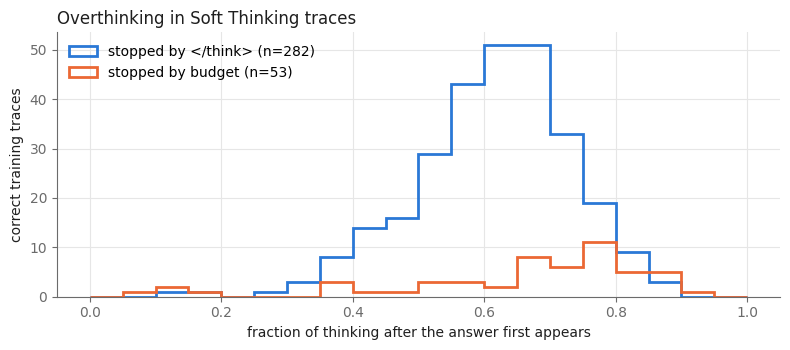

In [12]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.titlelocation": "left", "axes.titlecolor": INK})
GRAY = "#8a8a8a"

fig, ax = plt.subplots(figsize=(8, 3.6))
for stop, c in (("</think>", BLUE), ("budget", ORANGE)):
    v = known.loc[known["stop"] == stop, "after_answer"]
    if len(v):
        ax.hist(v, bins=np.linspace(0, 1, 21), histtype="step", linewidth=2, color=c, label=f"stopped by {stop} (n={len(v)})")
ax.set_xlabel("fraction of thinking after the answer first appears"); ax.set_ylabel("correct training traces")
ax.set_title("Overthinking in Soft Thinking traces"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

---
# Part 4: Calibration on training traces

For each $(\tau, k)$ we compute where Cold Stop would fire on every training trace. It fires at the first step that completes a run of $k$ steps with entropy below $\tau$, and only counts if that is before the trace's original end. From that we get the token savings and the harm rate, then apply the selection rule.

In [13]:
def cold_stop_step(entropies_, tau, k):
    """First step index at which `k` consecutive entropies < tau are reached, or None."""
    low = (np.asarray(entropies_) < tau).astype(np.int32)
    if len(low) < k:
        return None
    run = np.convolve(low, np.ones(k, dtype=np.int32), mode="valid")
    hit = np.flatnonzero(run >= k)
    return int(hit[0] + k - 1) if len(hit) else None


def simulate(traces, tau, k):
    """New thinking length per trace and harm statistics if Cold Stop used (tau, k)."""
    total_old = total_new = fired = harmed = harm_den = 0
    for r in traces:
        L = r["think_tokens"]
        t = cold_stop_step([s["entropy"] for s in r["steps"]], tau, k)
        cut = t is not None and t < L - 1            # must fire before the original stopping step
        new_len = t + 1 if cut else L
        total_old += L; total_new += new_len; fired += cut
        a = r.get("_ans_step")
        if r["correct"] and a is not None:
            harm_den += 1
            harmed += cut and (a == -1 or a >= t)    # cut before the answer was written (fed steps are < t)
    return {"tau": tau, "k": k, "fires on": fired / len(traces), "token savings": 1 - total_new / total_old,
            "harm rate": harmed / max(harm_den, 1)}


grid = pd.DataFrame([simulate(train_traces, tau, k) for tau in CFG.cal_taus for k in CFG.cal_lens])
ok = grid[grid["harm rate"] <= CFG.harm_target]
best = ok.loc[ok["token savings"].idxmax()] if len(ok) and ok["token savings"].max() > 0 else None
if best is None:
    CAL = {"tau": CFG.cold_stop_tau, "len": CFG.cold_stop_len, "calibrated": False}
    print("No setting saves tokens within the harm target: keeping the paper's Cold Stop.")
else:
    CAL = {"tau": float(best["tau"]), "len": int(best["k"]), "calibrated": True,
           "train_token_savings": float(best["token savings"]), "train_harm_rate": float(best["harm rate"]),
           "train_fires_on": float(best["fires on"])}
CAL["harm_target"] = CFG.harm_target
paper_setting = simulate(train_traces, CFG.cold_stop_tau, CFG.cold_stop_len)
print(f"paper setting (tau={CFG.cold_stop_tau}, k={CFG.cold_stop_len}): fires on {paper_setting['fires on']:.0%}, "
      f"saves {paper_setting['token savings']:.1%}")
print(f"CALIBRATED: tau={CAL['tau']}, k={CAL['len']}" + (f" | train: fires on {CAL['train_fires_on']:.0%}, "
      f"saves {CAL['train_token_savings']:.1%} of thinking tokens, harm {CAL['train_harm_rate']:.1%}" if CAL["calibrated"] else ""))
grid.round(3)

paper setting (tau=0.01, k=128): fires on 0%, saves 0.0%
CALIBRATED: tau=0.25, k=96 | train: fires on 2%, saves 1.4% of thinking tokens, harm 0.9%


,tau,k,fires on,token savings,harm rate
0,0.01,16,1.000,0.967,0.991
1,0.01,32,0.800,0.667,0.660
2,0.01,48,0.318,0.247,0.186
3,0.01,64,0.125,0.085,0.053
4,0.01,96,0.020,0.014,0.006
5,0.01,128,0.000,0.000,0.000
6,0.01,192,0.000,0.000,0.000
7,0.01,256,0.000,0.000,0.000
8,0.05,16,1.000,0.967,0.991
9,0.05,32,0.800,0.667,0.660


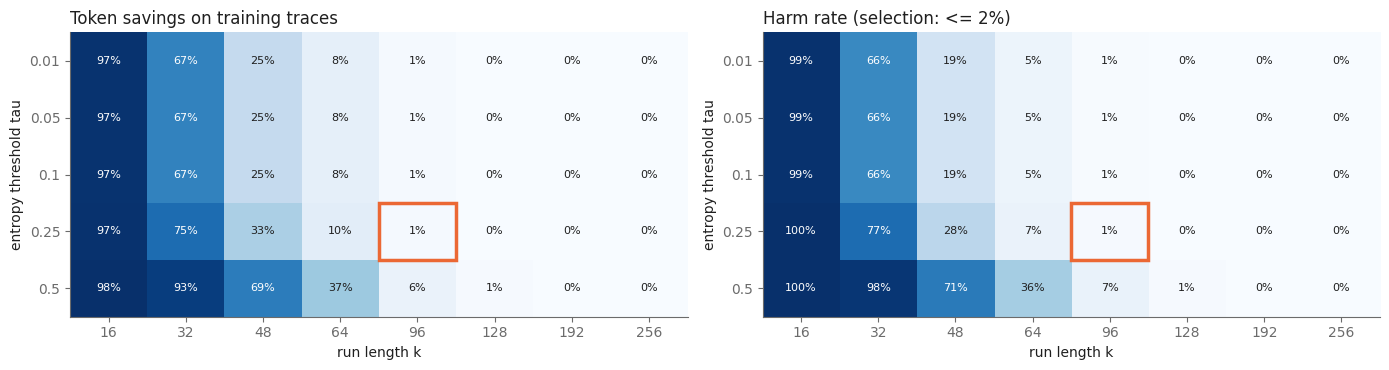

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, col, title in ((axes[0], "token savings", "Token savings on training traces"),
                       (axes[1], "harm rate", f"Harm rate (selection: <= {CFG.harm_target:.0%})")):
    mat = grid.pivot(index="tau", columns="k", values=col)
    im = ax.imshow(mat.values, cmap="Blues", aspect="auto", vmin=0, vmax=max(mat.values.max(), 1e-9))
    ax.set_xticks(range(mat.shape[1]), mat.columns); ax.set_yticks(range(mat.shape[0]), mat.index)
    ax.set_xlabel("run length k"); ax.set_ylabel("entropy threshold tau"); ax.set_title(title); ax.grid(False)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 * max(mat.values.max(), 1e-9) else INK)
    if CAL["calibrated"]:
        ax.add_patch(plt.Rectangle((list(mat.columns).index(CAL["len"]) - 0.5, list(mat.index).index(CAL["tau"]) - 0.5),
                                   1, 1, fill=False, edgecolor=ORANGE, linewidth=2.5))
plt.tight_layout(); plt.show()

with open(f"{OUT_DIR}/cold_stop_calibration.json", "w") as f:
    json.dump(CAL, f, indent=2)

In [15]:
# For reference only (not used for selection): what the simulation predicts on Notebook 1's test traces.
for r in paper_test:
    r["_ans_step"] = answer_step(r)
pred = simulate(paper_test, CAL["tau"], CAL["len"])
print(f"predicted on test traces: fires on {pred['fires on']:.0%}, saves {pred['token savings']:.1%} of thinking tokens, "
      f"harm proxy {pred['harm rate']:.1%}")

predicted on test traces: fires on 3%, saves 1.8% of thinking tokens, harm proxy 0.0%


---
# Part 5: Evaluation on the test questions

The run is identical to Notebook 1 except for the calibrated Cold Stop. It is followed by the gap diagnosis, which Notebook 4 compares against.

In [16]:
CFG_CCS = replace(CFG, cold_stop_tau=CAL["tau"], cold_stop_len=CAL["len"])
print("Cold Stop for this run:", CFG_CCS.cold_stop_tau, CFG_CCS.cold_stop_len)
ccs_test = run_soft_thinking(test_set, "ccs_test", cfg=CFG_CCS)
diag_ccs = diagnose_run(ccs_test, "diag_ccs")

Cold Stop for this run: 0.25 96
[ccs_test]   16/250 | batch  311.3s | elapsed   5.2 min | running acc 0.938
[ccs_test]   32/250 | batch  307.4s | elapsed  10.3 min | running acc 0.906
[ccs_test]   48/250 | batch  317.5s | elapsed  15.6 min | running acc 0.896
[ccs_test]   64/250 | batch  312.1s | elapsed  20.8 min | running acc 0.891
[ccs_test]   80/250 | batch  292.1s | elapsed  25.7 min | running acc 0.900
[ccs_test]   96/250 | batch  309.5s | elapsed  30.8 min | running acc 0.885
[ccs_test]  112/250 | batch  294.4s | elapsed  35.7 min | running acc 0.884
[ccs_test]  128/250 | batch  315.0s | elapsed  41.0 min | running acc 0.875
[ccs_test]  144/250 | batch  287.2s | elapsed  45.8 min | running acc 0.882
[ccs_test]  160/250 | batch  288.0s | elapsed  50.6 min | running acc 0.875
[ccs_test]  176/250 | batch  314.1s | elapsed  55.8 min | running acc 0.881
[ccs_test]  192/250 | batch  318.5s | elapsed  61.1 min | running acc 0.880
[ccs_test]  208/250 | batch  315.7s | elapsed  66.4 min 

In [17]:
# Check of the simulation: where the calibrated Cold Stop actually fired vs where it was predicted to fire.
by_id = {r["id"]: r for r in paper_test}
agree = []
for r in ccs_test:
    p = by_id[r["id"]]
    t = cold_stop_step([s["entropy"] for s in p["steps"]], CAL["tau"], CAL["len"])
    predicted = t + 1 if (t is not None and t < p["think_tokens"] - 1) else p["think_tokens"]
    agree.append(predicted == r["think_tokens"])
print(f"thinking length exactly as predicted from Notebook 1's traces: {np.mean(agree):.0%} of questions "
      "(differences come from tiny batched floating-point effects)")

thinking length exactly as predicted from Notebook 1's traces: 100% of questions (differences come from tiny batched floating-point effects)


---
# Part 6: Comparison with the paper's Cold Stop

In [18]:
NAMES = ("Soft Thinking (paper)", "+ calibrated Cold Stop")
main_table = pd.DataFrame([summarize(paper_test, NAMES[0]), summarize(ccs_test, NAMES[1])]).set_index("system")
main_table.loc[NAMES[0], "test decoding (min)"] = paper_time["seconds"] / 60
main_table.loc[NAMES[1], "test decoding (min)"] = json.load(open(f"{OUT_DIR}/ccs_test_time.json"))["seconds"] / 60
display(main_table.round(3))

acc_table, acc_test = paired_accuracy(paper_test, ccs_test, "paper", "calibrated")
display(acc_table)
tok_test = paired_tokens(paper_test, ccs_test)
tests = pd.DataFrame([{**acc_test, **{f"tokens: {k}": v for k, v in tok_test.items()}}])
tests.T

,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition,test decoding (min)
system,,,,,,,,,
Soft Thinking (paper),0.892,1342.180,0.720,0.000,0.280,0.036,0.214,0.174,82.565
+ calibrated Cold Stop,0.892,1317.368,0.704,0.028,0.268,0.040,0.214,0.173,79.320


,calibrated correct,calibrated wrong
paper correct,223,0
paper wrong,0,27


,0
comparison,calibrated vs paper
questions,250
paper-only correct,0
calibrated-only correct,0
McNemar p,1.0
tokens: mean tokens a,1342.18
tokens: mean tokens b,1317.368
tokens: relative change,-0.018486
tokens: b shorter on,3%
tokens: Wilcoxon p,0.01796


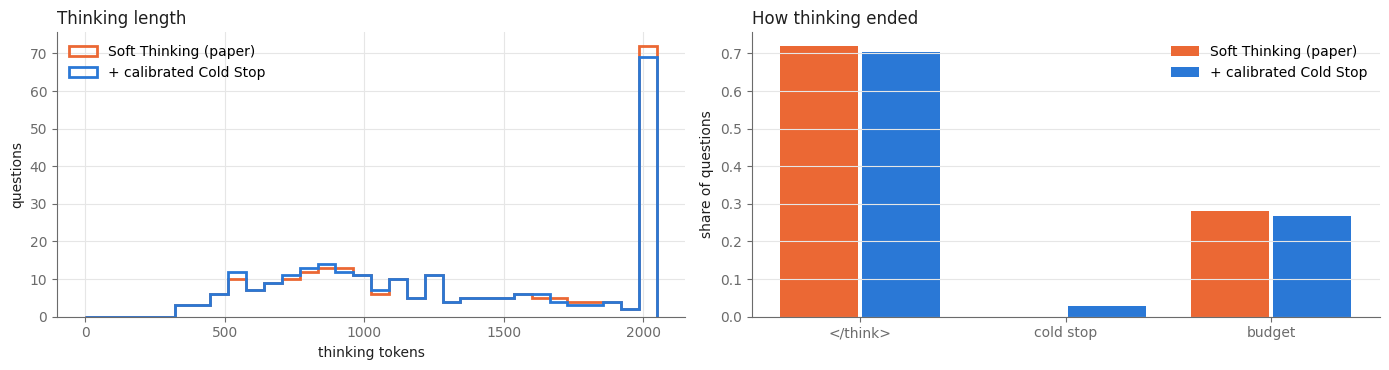

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
ax = axes[0]
bins = np.linspace(0, CFG.max_think_tokens, 33)
ax.hist([r["think_tokens"] for r in paper_test], bins=bins, histtype="step", linewidth=2, color=ORANGE, label=NAMES[0])
ax.hist([r["think_tokens"] for r in ccs_test], bins=bins, histtype="step", linewidth=2, color=BLUE, label=NAMES[1])
ax.set_xlabel("thinking tokens"); ax.set_ylabel("questions"); ax.set_title("Thinking length"); ax.legend(frameon=False)

ax = axes[1]
stops = ["</think>", "cold stop", "budget"]
x = np.arange(len(stops)); w = 0.38
for off, (name, res, c) in zip((-w/2 - 0.01, w/2 + 0.01), ((NAMES[0], paper_test, ORANGE), (NAMES[1], ccs_test, BLUE))):
    ax.bar(x + off, [np.mean([r["stop_reason"] == s for r in res]) for s in stops], w, color=c, label=name)
ax.set_xticks(x, stops); ax.set_ylabel("share of questions"); ax.set_title("How thinking ended")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

---
# Part 7: Conclusion

In [20]:
m = main_table
print(f"""CALIBRATED COLD STOP: tau = {CAL['tau']}, k = {CAL['len']} (paper setting: tau = {CFG.cold_stop_tau}, k = {CFG.cold_stop_len})
  chosen on training traces only: harm <= {CFG.harm_target:.0%}, max token savings

ACCURACY
  paper {m.loc[NAMES[0], 'accuracy']:.1%} vs calibrated {m.loc[NAMES[1], 'accuracy']:.1%} | McNemar p = {acc_test['McNemar p']:.3f}
  paper-only correct {acc_test['paper-only correct']}, calibrated-only correct {acc_test['calibrated-only correct']}

EFFICIENCY
  avg thinking tokens {tok_test['mean tokens a']:.0f} -> {tok_test['mean tokens b']:.0f} ({tok_test['relative change']:+.1%}), Wilcoxon p = {tok_test['Wilcoxon p']:.2g}
  shorter on {tok_test['b shorter on']} of questions | Cold Stop fired on {m.loc[NAMES[1], 'stop: cold stop']:.0%} (paper: {m.loc[NAMES[0], 'stop: cold stop']:.0%})
  budget reached {m.loc[NAMES[0], 'stop: budget']:.0%} -> {m.loc[NAMES[1], 'stop: budget']:.0%} | test decoding {m.loc[NAMES[0], 'test decoding (min)']:.0f} -> {m.loc[NAMES[1], 'test decoding (min)']:.0f} min""")

main_table.to_csv(f"{OUT_DIR}/ccs_results.csv")
grid.to_csv(f"{OUT_DIR}/calibration_grid.csv", index=False)
tests.to_csv(f"{OUT_DIR}/ccs_tests.csv", index=False)
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump({"run_mode": RUN_MODE, "model": MODEL_NAME, "notebook1_dir": NB1_DIR, "notebook2_dir": NB2_DIR,
               "calibration": CAL, **asdict(CFG)}, f, indent=2)
print("\nsaved:", sorted(os.listdir(OUT_DIR)))

CALIBRATED COLD STOP: tau = 0.25, k = 96 (paper setting: tau = 0.01, k = 128)
  chosen on training traces only: harm <= 2%, max token savings

ACCURACY
  paper 89.2% vs calibrated 89.2% | McNemar p = 1.000
  paper-only correct 0, calibrated-only correct 0

EFFICIENCY
  avg thinking tokens 1342 -> 1317 (-1.8%), Wilcoxon p = 0.018
  shorter on 3% of questions | Cold Stop fired on 3% (paper: 0%)
  budget reached 28% -> 27% | test decoding 83 -> 79 min

saved: ['calibration_grid.csv', 'ccs_results.csv', 'ccs_test.pkl', 'ccs_test_time.json', 'ccs_tests.csv', 'cold_stop_calibration.json', 'config.json', 'diag_ccs.pkl']


**Interpretation.**

* **Why this matters.** The paper claims Soft Thinking reasons with fewer tokens, partly through Cold Stop. With large-model settings Cold Stop is inactive on a 1.7B model. Calibrating it is a training-free, label-light fix: the gold answers of training questions are used only to *evaluate* candidate settings, never to train anything.
* **How to read the result.**
  * **Efficiency gain:** a significant token reduction (Wilcoxon) with a non-significant accuracy change (McNemar).
  * **Speed-accuracy trade-off:** a token reduction together with a significant accuracy drop. The harm proxy would then be too optimistic, and that should be reported as such.
* **Limitations.**
  * The harm proxy, "the answer has appeared in the thinking", does not guarantee that the model's final answer survives the cut.
  * Calibration is per model and per task.
  * One run.